In [1]:
import csv

RAT = "/users/yakshadevi/Chicago-Rat-Project/chicago_rat_project/rat_raw.csv"

with open(RAT, 'r') as infile, open('rat_reordered.csv', 'w') as outfile:
    # output dict needs a list for new column ordering
    fieldnames = ['Community Area', 'Creation Date', 'Status', 'Completion Date', 'Service Request Number', 'Type of Service Request', 'Number of Premises Baited', 'Number of Premises with Garbage', 'Number of Premises with Rats', 'Current Activity', 'Most Recent Action','Street Address', 'ZIP Code', 'X Coordinate', 'Y Coordinate', 'Ward', 'Police District', 'Latitude', 'Longitude', 'Location']
    writer = csv.DictWriter(outfile, fieldnames=fieldnames)
    # reorder the header first
    writer.writeheader()
    for row in csv.DictReader(infile):
        # writes the reordered rows to the new file
        writer.writerow(row)

In [2]:
import csv

UNEM = "/users/yakshadevi/Chicago-Rat-Project/chicago_rat_project/Unemployment.csv"

with open(UNEM, 'r') as infile, open('unemployment_reordered.csv', 'w') as outfile:
    # output dict needs a list for new column ordering
    fieldnames = ['Community Area', 'Name', 'UMP_2020-2024', 'UMP_2020-2024_moe', 'Layer']
    writer = csv.DictWriter(outfile, fieldnames=fieldnames)
    # reorder the header first
    writer.writeheader()
    for row in csv.DictReader(infile):
        # writes the reordered rows to the new file
        writer.writerow(row)

In [3]:
import pandas as pd

DIR = "/Users/yakshadevi/Chicago-Rat-Project/chicago_rat_project/"

# read as strings: the rat file has values like "14." that pandas can't treat as ints
rat = pd.read_csv(DIR + "rat_reordered.csv", dtype=str)


# "14." -> 14 so it matches the integer key in the unemployment file
rat["Community Area"] = pd.to_numeric(rat["Community Area"], errors="coerce").astype("Int64")

ump = pd.read_csv(DIR + "unemployment_reordered.csv")[["Community Area", "Name", "UMP_2020-2024"]]

# left join keeps every rat row; validate guards against duplicate keys in ump
merged = rat.merge(ump, on="Community Area", how="left", validate="many_to_one")
merged.to_csv(DIR + "rat_with_unemployment.csv", index=False)

In [4]:
import sys, pandas as pd
from chicago_rat_project.features import add_time_features

DIR = "/Users/yakshadevi/Chicago-Rat-Project/chicago_rat_project/"
df = pd.read_csv(DIR + "rat_with_unemployment.csv", low_memory=False)

# 1. drop duplicate requests (same Service Request Number)
df = df.drop_duplicates(subset="Service Request Number")
df = df[~df["Status"].str.contains("Dup", na=False)]

# 2. numeric-only premises columns
for col in ["Number of Premises Baited", "Number of Premises with Garbage", "Number of Premises with Rats"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")  
    premises_cols = ["Number of Premises Baited",
                 "Number of Premises with Garbage",
                 "Number of Premises with Rats"]

df[premises_cols] = df[premises_cols].apply(pd.to_numeric, errors="coerce").fillna(0)
# 3. drop columns that are not useful for analysis
DEFAULT_DROP_COLUMNS = (
    "Street Address",
    "X Coordinate",
    "Y Coordinate",
    "Location",
    "Ward",
    "Current Activity",
    "Type of Service Request",
) 

drop_columns = DEFAULT_DROP_COLUMNS
df = df.drop(columns=list(drop_columns), errors="ignore")

# 4. weekday-only elapsed time (uses PyWeekends via your features.py)
df = add_time_features(df).rename(columns={"Time to completion": "Request Completion Time"})

# 5. weekday/weekend label for Creation Date
created = pd.to_datetime(df["Creation Date"], format="%m/%d/%Y", errors="coerce")
df["Request Type"] = created.dt.day_of_week.map(lambda d: pd.NA if pd.isna(d) else ("Weekend" if d >= 5 else "Weekday")) 

# 6. Rename the unemployment column for clarity
df = df.rename(columns={"UMP_2020-2024": "Unemployment Rate"})

Number of Premises with Rats      -0.045511
Community Area                    -0.034151
Number of Premises with Garbage   -0.026962
Unemployment Rate                 -0.024782
Number of Premises Baited         -0.021759
Longitude                         -0.009537
Zip Code                          -0.000416
Request Type (Weekend=1)           0.011198
Police District                    0.022771
Latitude                           0.034897
Request Completion Time            1.000000
Name: Request Completion Time, dtype: float64


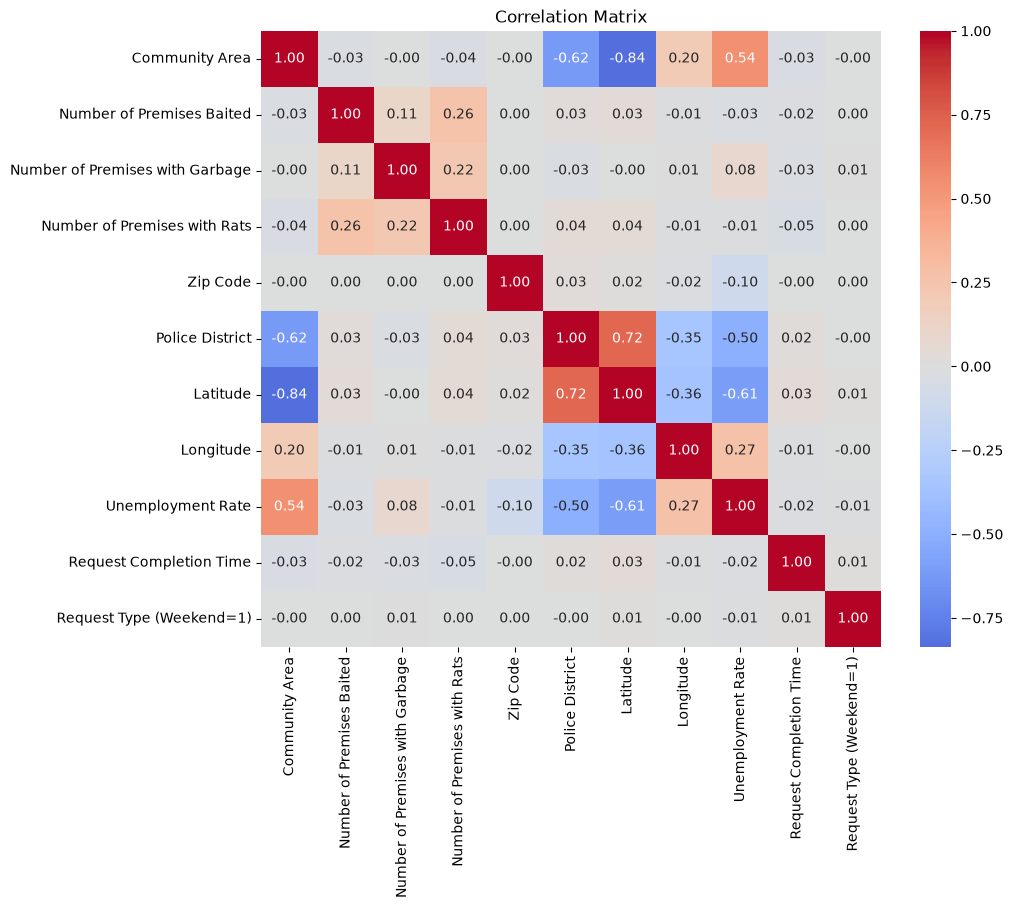

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# encode Request Type as a number first (Weekday = 0, Weekend = 1)
df["Request Type (Weekend=1)"] = df["Request Type"].map({"Weekday": 0, "Weekend": 1})

corr = df.corr(numeric_only=True)
print(corr["Request Completion Time"].sort_values())

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler 

selected_features = ['Unemployment Rate', 'Police District', 'Community Area']
X = df[selected_features]
y = df['Request Type'].map({"Weekday": 0, "Weekend": 1})  # convert to binary labels

# Initialize the StandardScaler object
scaler = StandardScaler()

# Fit the scaler to the data and transform it
X_scaled = scaler.fit_transform(X)

# Print the scaled data
print(X_scaled)

[[-0.33018127  0.43399897 -0.74168919]
 [ 0.74959546 -1.89084395  0.31848013]
 [-0.23201975  0.89896755 -1.25057047]
 ...
 [ 1.24040306 -0.65092773 -0.1055876 ]
 [-1.05657653  0.74397802 -1.08094337]
 [-0.36944588  1.05395708  0.40329368]]


In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

selected_features = ['Unemployment Rate', 'Police District', 'Community Area']          # add more columns here
data = df[selected_features].assign(y=df['Request Type'].map({"Weekday": 0, "Weekend": 1})).dropna()
X, y = data[selected_features], data['y']

# stratify keeps the ~10% weekend share in both splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# fit the scaler on training data only, to avoid leaking test information
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

model = LogisticRegression(class_weight="balanced", max_iter=1000)
model.fit(X_train_s, y_train)

y_pred = model.predict(X_test_s)
y_prob = model.predict_proba(X_test_s)[:, 1]

baseline = DummyClassifier(strategy="most_frequent").fit(X_train_s, y_train).score(X_test_s, y_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}   (always-Weekday baseline: {baseline:.3f})")
print(f"ROC AUC:  {roc_auc_score(y_test, y_prob):.3f}   (0.5 = no better than chance)")
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=["Weekday", "Weekend"]))

Accuracy: 0.453   (always-Weekday baseline: 0.898)
ROC AUC:  0.517   (0.5 = no better than chance)
[[23431 30111]
 [ 2520  3547]]
              precision    recall  f1-score   support

     Weekday       0.90      0.44      0.59     53542
     Weekend       0.11      0.58      0.18      6067

    accuracy                           0.45     59609
   macro avg       0.50      0.51      0.38     59609
weighted avg       0.82      0.45      0.55     59609



In [8]:

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

data = df[["Unemployment Rate", "Name"]].assign(
    y=df["Request Type"].map({"Weekday": 0, "Weekend": 1})).dropna()
X, y = data[["Unemployment Rate"]], data["y"]

scaler = StandardScaler().fit(X)
model = LogisticRegression(max_iter=1000).fit(scaler.transform(X), y)

# fitted curve across the observed range
grid = pd.DataFrame({"Unemployment Rate": np.linspace(X.iloc[:, 0].min(), X.iloc[:, 0].max(), 200)})
grid["p"] = model.predict_proba(scaler.transform(grid))[:, 1]

# actual data: weekend share per neighborhood (raw 0/1 points would just overlap)
areas = (data.groupby(["Name", "Unemployment Rate"])["y"]
             .agg(weekend_share="mean", requests="size").reset_index())

fig = go.Figure()
fig.add_trace(go.Scatter(
    x=areas["Unemployment Rate"], y=areas["weekend_share"], mode="markers",
    name="Actual (per neighborhood)",
    marker=dict(size=np.sqrt(areas["requests"]) / 2.5, opacity=0.6),
    customdata=areas[["Name", "requests"]],
    hovertemplate="<b>%{customdata[0]}</b><br>Unemployment: %{x:.1f}%<br>"
                  "Actual weekend share: %{y:.1%}<br>Requests: %{customdata[1]:,}<extra></extra>"))
fig.add_trace(go.Scatter(
    x=grid["Unemployment Rate"], y=grid["p"], mode="lines", name="Logistic regression fit",
    line=dict(width=3),
    hovertemplate="Unemployment: %{x:.1f}%<br>Predicted P(weekend): %{y:.1%}<extra></extra>"))
fig.add_hline(y=y.mean(), line_dash="dot", annotation_text=f"Overall weekend share {y.mean():.1%}")
fig.update_layout(title="Weekend request probability vs. unemployment rate",
                  xaxis_title="Unemployment Rate (%)", yaxis_title="P(request created on a weekend)",
                  yaxis_tickformat=".0%")
fig.show()